<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/05_sequences/notebooks/sesion_05_2_rnn_bptt.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/05_sequences/notebooks/sesion_05_2_rnn_bptt.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F05_sequences%2Fnotebooks%2Fsesion_05_2_rnn_bptt.ipynb)

# SI7011 · Sesión 05 · 2. Una red recurrente y su gradiente en el tiempo
**Juan David Martínez Vargas · Universidad EAFIT**

Acompaña la **Parte 2** de las diapositivas. La misma tarea del notebook 1: 5 días de Jena → temperatura en 24 horas. Ahora con una red que lee la ventana hora por hora y guarda un resumen $\mathbf h_t$.

| Sección | Lo que cambia | Qué mirar |
|---|---|---|
| 1 | la celda escrita como un `for` | que da lo mismo que `nn.RNN` |
| 2 | entrenar la RNN | ¿le gana a la línea base? |
| 3 | $\lVert \partial L / \partial \mathbf x_t \rVert$ para cada hora $t$ | hasta dónde llega el gradiente |
| 4 | la norma del gradiente durante el entrenamiento | qué hace el *clipping* |
| 5 | ventana de 1 día frente a 5 días | qué ganan los 4 días extra |

**Datos:** Jena Climate, la misma partición y las mismas ventanas del notebook 1. Corre en CPU en unos 3 minutos. **En Kaggle:** agrega el dataset [`mnassrib/jena-climate`](https://www.kaggle.com/datasets/mnassrib/jena-climate) con **Add Input**.

In [1]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__)

PyTorch 2.14.1+cu130


## Datos: Jena, como en el notebook 1
Misma carga, misma partición 50/25/25 en el tiempo, misma normalización con train, mismas ventanas de $T = 120$ horas.

### Cargar Jena Climate
La celda busca `jena_climate_2009_2016.csv` en este orden y usa el primero que encuentre. Imprime la **fuente** usada: revísala.

| Plataforma | De dónde salen los datos |
|---|---|
| **Kaggle** | el dataset [`mnassrib/jena-climate`](https://www.kaggle.com/datasets/mnassrib/jena-climate) agregado con **Add Input** (`/kaggle/input/...`), sin descargar |
| **Lightning Studio** o **local** | la carpeta `data/` junto al notebook |
| **Colab** | `kagglehub` con el mismo dataset y tu secreto `KAGGLE_API_TOKEN` (el mismo de la sesión 01) |

In [2]:
import os
from pathlib import Path

KAGGLE_HANDLE = 'mnassrib/jena-climate'
ARCHIVO = 'jena_climate_2009_2016.csv'
ROOTS = [Path('data'), Path('/kaggle/input'), Path('/teamspace/studios/this_studio/data')]

def kaggle_token():
    # Colab: secreto KAGGLE_API_TOKEN. Local o Lightning: variable de entorno o ~/.kaggle/access_token.
    if 'KAGGLE_API_TOKEN' not in os.environ:
        try:
            from google.colab import userdata
            os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN').strip()
        except Exception:
            pass
    return 'KAGGLE_API_TOKEN' in os.environ or (Path.home() / '.kaggle' / 'access_token').exists()

def buscar_csv():
    for root in ROOTS:
        if root.exists():
            hits = sorted(root.rglob(ARCHIVO))
            if hits:
                return hits[0], str(root)
    if kaggle_token():
        import kagglehub
        path = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
        return sorted(path.rglob(ARCHIVO))[0], f'kagglehub {KAGGLE_HANDLE}'
    raise FileNotFoundError(f'No encontré {ARCHIVO}: agrégalo con Add Input (Kaggle), ponlo en data/ o configura KAGGLE_API_TOKEN.')

ruta, fuente = buscar_csv()
print('fuente:', fuente, '·', ruta)
with open(ruta) as f:
    COLUMNAS = [c.strip('"') for c in f.readline().strip().split(',')][1:]   # sin 'Date Time'
crudo = np.loadtxt(ruta, delimiter=',', skiprows=1, usecols=range(1, 15), dtype=np.float32)
# El anemómetro marca −9999 cuando falla. Una velocidad negativa no existe: se reemplaza por 0 (sin viento).
VIENTO = [COLUMNAS.index('wv (m/s)'), COLUMNAS.index('max. wv (m/s)')]
errores = crudo[:, VIENTO] < 0
crudo[:, VIENTO] = np.where(errores, 0.0, crudo[:, VIENTO])
fechas = np.loadtxt(ruta, delimiter=',', skiprows=1, usecols=0, dtype=str)            # 'dd.mm.aaaa hh:mm:ss'
iso = np.array([f'{f[6:10]}-{f[3:5]}-{f[0:2]}T{f[11:19]}' for f in fechas], dtype='datetime64[s]')

# Contrato de datos: una fila por instante y una lectura por hora, elegida por su marca de tiempo (minuto :00),
# no por su posición en el archivo. Así no importa si la copia tiene filas repetidas o le faltan algunas.
_, primera = np.unique(iso, return_index=True)                 # quita marcas de tiempo repetidas (se queda con la primera)
primera = np.sort(primera)
en_punto = (iso[primera].astype('datetime64[m]') - iso[primera].astype('datetime64[h]')) == np.timedelta64(0, 'm')
filas = primera[en_punto]
datos, horas = crudo[filas], iso[filas].astype('datetime64[h]')
temp = datos[:, COLUMNAS.index('T (degC)')]
saltos = np.diff(horas) != np.timedelta64(1, 'h')
print(f'{len(crudo):,} lecturas cada 10 min · {len(iso) - len(primera)} marcas de tiempo repetidas (quitadas) · {int(errores.sum())} lecturas de viento = −9999 (puestas en 0)')
print(f'{len(datos):,} horas · {datos.shape[1]} variables · {int(saltos.sum())} huecos en la serie horaria')

fuente: data · data/jena_climate_2009_2016.csv


420,551 lecturas cada 10 min · 327 marcas de tiempo repetidas (quitadas) · 38 lecturas de viento = −9999 (puestas en 0)
70,037 horas · 14 variables · 4 huecos en la serie horaria


In [3]:
N = len(datos)
I_VAL, I_TEST = int(0.5 * N), int(0.75 * N)            # 50 % train · 25 % validación · 25 % prueba, en orden
T, H_FUT = 120, 24                                     # 5 días de entrada → temperatura 24 h después
mu, sd = datos[:I_VAL].mean(0), datos[:I_VAL].std(0)   # estadísticos SOLO del pasado (train)
Xn = (datos - mu) / sd
J_T = COLUMNAS.index('T (degC)')

def inicios(a, b, T=T):
    """Inicios de ventana cuyo objetivo (t + T - 1 + H_FUT) cae dentro del bloque [a, b),
    y que no saltan un hueco de la serie: de la primera hora al objetivo hay exactamente T - 1 + H_FUT horas."""
    ini = np.arange(a, b - T - H_FUT + 1)
    seguidas = (horas[ini + T - 1 + H_FUT] - horas[ini]) == np.timedelta64(T - 1 + H_FUT, 'h')
    return ini[seguidas]

tr, va, te = inicios(0, I_VAL), inicios(I_VAL, I_TEST), inicios(I_TEST, N)
base_val = np.abs(temp[va + T - 1] - temp[va + T - 1 + H_FUT]).mean()
print(f'{len(tr):,} ventanas de train · línea base {base_val:.2f} °C (notebook 1)')

34,732 ventanas de train · línea base 2.44 °C (notebook 1)


## Herramientas: ventanas, loop y MAE
Las mismas del notebook 1. `entrenar` puede guardar la norma del gradiente de cada paso (sección 4).

In [4]:
class Ventanas(torch.utils.data.Dataset):
    """x = T horas de las 14 variables normalizadas; y = temperatura normalizada H_FUT horas después."""
    def __init__(self, inicios, T=T):
        self.inicios, self.T = inicios, T
    def __len__(self):
        return len(self.inicios)
    def __getitem__(self, i):
        a = self.inicios[i]
        return torch.from_numpy(Xn[a:a + self.T]), torch.tensor(Xn[a + self.T - 1 + H_FUT, J_T])

def cargador(inicios, T=T, barajar=False):
    return torch.utils.data.DataLoader(Ventanas(inicios, T), batch_size=256, shuffle=barajar)

@torch.no_grad()
def mae(modelo, inicios, T=T):
    """MAE en °C: el modelo predice la temperatura normalizada; se desnormaliza con sd de train."""
    modelo.eval()
    errores = [(modelo(x) - y).abs() for x, y in cargador(inicios, T)]
    return float(torch.cat(errores).mean().item() * sd[J_T])

def entrenar(modelo, inicios_train, inicios_val, T=T, epocas=8, lr=3e-3, recortar=1.0, normas=None):
    opt = torch.optim.Adam(modelo.parameters(), lr)
    t0 = time.time()
    for ep in range(epocas):
        modelo.train()
        for x, y in cargador(inicios_train, T, barajar=True):
            loss = nn.functional.mse_loss(modelo(x), y)
            opt.zero_grad(); loss.backward()
            norma = nn.utils.clip_grad_norm_(modelo.parameters(), recortar)   # devuelve la norma ANTES de recortar
            if normas is not None:
                normas.append(norma.item())
            opt.step()
        print(f'época {ep + 1}: MAE validación {mae(modelo, inicios_val, T):.3f} °C')
    print(f'{time.time() - t0:.0f} s · {sum(p.numel() for p in modelo.parameters()):,} parámetros')
    return modelo

## 1. La celda, escrita como un `for`
$$
\mathbf h_t = \tanh\big(W_{xh}\,\mathbf x_t + W_{hh}\,\mathbf h_{t-1} + \mathbf b\big), \qquad \mathbf h_0 = \mathbf 0
$$
Los **mismos** $W_{xh}$, $W_{hh}$ y $\mathbf b$ en cada hora. Escribimos el bucle a mano con los pesos de un `nn.RNN` y comparamos.

In [5]:
torch.manual_seed(0)
rnn = nn.RNN(input_size=14, hidden_size=16, batch_first=True)          # φ = tanh por defecto
x, _ = next(iter(cargador(va[:8])))                                    # (B, T, 14)

def rnn_a_mano(x, rnn):
    W_xh, W_hh = rnn.weight_ih_l0, rnn.weight_hh_l0                    # PyTorch usa dos sesgos; su suma es b
    b = rnn.bias_ih_l0 + rnn.bias_hh_l0
    h = torch.zeros(x.shape[0], W_hh.shape[0])                         # h_0 = 0
    estados = []
    for t in range(x.shape[1]):                                        # un paso por hora
        h = torch.tanh(x[:, t] @ W_xh.T + h @ W_hh.T + b)
        estados.append(h)
    return torch.stack(estados, 1)                                     # (B, T, 16): todos los h_t

with torch.no_grad():
    salida, h_T = rnn(x)
    print('salida', tuple(salida.shape), '· h_T', tuple(h_T.shape))
    print('diferencia máxima con el for:', (salida - rnn_a_mano(x, rnn)).abs().max().item())

salida (8, 120, 16) · h_T (1, 8, 16)
diferencia máxima con el for: 1.1920928955078125e-07


`salida` trae todos los $\mathbf h_t$; `h_T` solo el último. Para una predicción *many-to-one* leemos `salida[:, -1]`. La cantidad de parámetros no depende de $T$: 120 horas o 12 000, la celda es la misma.

## 2. Entrenar la RNN
16 unidades y una capa lineal sobre $\mathbf h_T$. Antes de correr: ¿supera la línea base de 2.44 °C?

In [6]:
class RNN(nn.Module):
    def __init__(self, oculta=16):
        super().__init__()
        self.rnn = nn.RNN(14, oculta, batch_first=True)
        self.salida = nn.Linear(oculta, 1)
    def forward(self, x):
        h, _ = self.rnn(x)                     # (B, T, oculta)
        return self.salida(h[:, -1]).squeeze(-1)   # ŷ = w·h_T + b

torch.manual_seed(0)
normas = []
modelo = entrenar(RNN(), tr, va, normas=normas)
mae_120 = mae(modelo, va)
print(f'línea base {base_val:.2f} °C · RNN {mae_120:.2f} °C')

época 1: MAE validación 2.368 °C


época 2: MAE validación 2.341 °C


época 3: MAE validación 2.351 °C


época 4: MAE validación 2.364 °C


época 5: MAE validación 2.338 °C


época 6: MAE validación 2.338 °C


época 7: MAE validación 2.330 °C


época 8: MAE validación 2.329 °C
23 s · 529 parámetros


línea base 2.44 °C · RNN 2.33 °C


La RNN **sí** supera la línea base, por poco, donde el MLP y la CNN 1-D del notebook 1 no lo lograban: leer en orden y resumir sirve.

## 3. ¿Hasta dónde llega el gradiente?
Para cada hora $t$ de la ventana medimos $\lVert \partial L / \partial \mathbf x_t \rVert$: cuánto cambiaría la pérdida si cambiara la entrada de esa hora. Es la señal con la que la red aprende a usar la hora $t$. En la diapositiva:

$$
\frac{\partial \mathbf h_T}{\partial \mathbf h_t} = \prod_{k=t+1}^{T} \operatorname{diag}\!\big(\varphi'(\mathbf z_k)\big)\, W_{hh}
$$

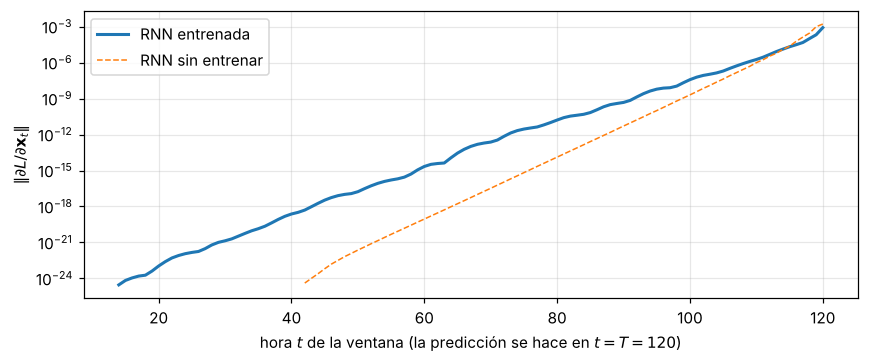

  0 horas antes del final: 1.0e+00 veces el gradiente de la última hora
 12 horas antes del final: 1.0e-03 veces el gradiente de la última hora
 24 horas antes del final: 9.1e-06 veces el gradiente de la última hora
 48 horas antes del final: 8.7e-10 veces el gradiente de la última hora
 96 horas antes del final: 1.4e-19 veces el gradiente de la última hora
horas con gradiente exactamente 0 (float32): 13


In [7]:
def gradiente_por_hora(modelo, n=256):
    modelo.eval()
    x, y = next(iter(cargador(va[::7][:n])))                          # 256 ventanas repartidas en validación
    x = x.clone().requires_grad_(True)
    nn.functional.mse_loss(modelo(x), y).backward()
    return x.grad.norm(dim=2).mean(0).numpy()                          # promedio sobre el lote, una por hora

torch.manual_seed(0)
g_inicial = gradiente_por_hora(RNN())                                  # pesos aleatorios, sin entrenar
g = gradiente_por_hora(modelo)

fig, ax = plt.subplots(figsize=(8, 3.4))
horas = np.arange(1, T + 1)
ax.semilogy(horas, np.where(g > 0, g, np.nan), lw=2, label='RNN entrenada')
ax.semilogy(horas, np.where(g_inicial > 0, g_inicial, np.nan), lw=1, ls='--', label='RNN sin entrenar')
ax.set_xlabel('hora $t$ de la ventana (la predicción se hace en $t = T = 120$)')
ax.set_ylabel(r'$\Vert \partial L / \partial \mathbf{x}_t \Vert$')
ax.legend(); plt.tight_layout(); plt.show()
for atras in (0, 12, 24, 48, 96):
    print(f'{atras:3d} horas antes del final: {g[T - 1 - atras] / g[-1]:.1e} veces el gradiente de la última hora')
print('horas con gradiente exactamente 0 (float32):', int((g == 0).sum()))

El gradiente cae **geométricamente**: cada 12 horas hacia atrás se divide por unas mil, y cuatro días antes del final es del orden de $10^{-19}$ veces el de la última hora. Para las primeras horas de la ventana es **exactamente cero** en `float32` (la última línea las cuenta; el número exacto cambia con la semilla). La red no puede aprender a usar lo que pasó hace más de un par de días: para ella, esas horas no existen. La recta en escala logarítmica es el producto de Jacobianos de la diapositiva: el mismo factor, repetido.

In [8]:
# Lo que lee la figura S05-F03 (make_s05_figuras_notebooks.py); el notebook 3 agrega LSTM y GRU
np.savez('gradiente_tiempo_rnn.npz', g=g, g_inicial=g_inicial)

## 4. El *clipping*, mirado
Durante el entrenamiento de la sección 2 guardamos la norma del gradiente de cada paso, **antes** de recortarla a 1.0.

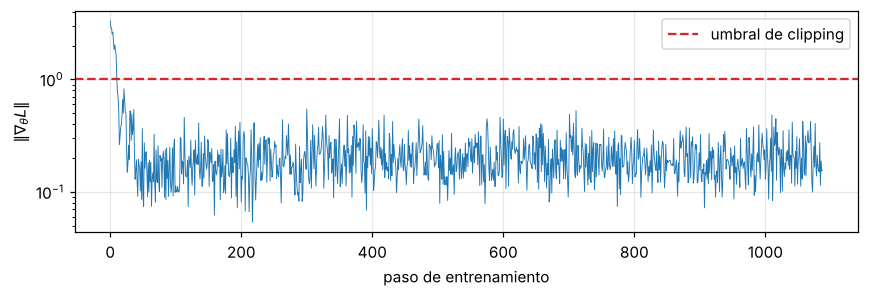

pasos recortados: 1.0% · norma máxima 3.31


In [9]:
normas = np.array(normas)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.semilogy(normas, lw=0.6); ax.axhline(1.0, color='C3', ls='--', label='umbral de clipping')
ax.set_xlabel('paso de entrenamiento'); ax.set_ylabel(r'$\Vert \nabla_\theta L \Vert$'); ax.legend()
plt.tight_layout(); plt.show()
print(f'pasos recortados: {(normas > 1).mean():.1%} · norma máxima {normas.max():.2f}')

Aquí el gradiente total casi nunca pasa del umbral: con tanh y 16 unidades lo usual es que el gradiente **se apague**, no que explote. El *clipping* es un seguro contra explosiones y no hace nada por la sección 3: un gradiente pequeño sigue siendo pequeño.

## 5. Un día frente a cinco
Si las primeras horas no reciben gradiente, ¿sirven de algo? Entrenamos la misma RNN con ventanas de $T = 24$ horas. Las ventanas terminan en las mismas horas que antes, así que el objetivo es el mismo.

In [10]:
def recortar(ini, T_nueva):                    # misma hora final: el inicio se corre T - T_nueva horas
    return ini + (T - T_nueva)

torch.manual_seed(0)
modelo_24 = entrenar(RNN(), recortar(tr, 24), recortar(va, 24), T=24)
mae_24 = mae(modelo_24, recortar(va, 24), T=24)
print(f'línea base {base_val:.2f} °C · RNN con 5 días {mae_120:.2f} °C · RNN con 1 día {mae_24:.2f} °C')

época 1: MAE validación 2.368 °C


época 2: MAE validación 2.341 °C


época 3: MAE validación 2.351 °C


época 4: MAE validación 2.364 °C


época 5: MAE validación 2.338 °C


época 6: MAE validación 2.338 °C


época 7: MAE validación 2.330 °C


época 8: MAE validación 2.329 °C
5 s · 529 parámetros
línea base 2.44 °C · RNN con 5 días 2.33 °C · RNN con 1 día 2.33 °C


Los cuatro días extra no ayudan: es lo que predice la sección 3. Y entrenar con 1 día es unas cinco veces más rápido. Para que lo lejano sirva, la red necesita un camino por el que el gradiente llegue sin apagarse: la Parte 3 (LSTM y GRU).

## Evaluación en prueba

In [11]:
resultados = {'base': {'val': float(base_val), 'test': float(np.abs(temp[te + T - 1] - temp[te + T - 1 + H_FUT]).mean())},
              'rnn_120h': {'val': mae_120, 'test': mae(modelo, te)},
              'rnn_24h': {'val': mae_24, 'test': mae(modelo_24, recortar(te, 24), T=24)}}
for k, v in resultados.items():
    print(f"{k:9s} validación {v['val']:.2f} °C · prueba {v['test']:.2f} °C")
json.dump(resultados, open('resultados_jena_52.json', 'w'), indent=1)

base      validación 2.44 °C · prueba 2.62 °C
rnn_120h  validación 2.33 °C · prueba 2.45 °C
rnn_24h   validación 2.33 °C · prueba 2.45 °C


## Tu turno · 10 minutos
1. Repite la sección 3 con `nn.RNN(..., nonlinearity='relu')`. ¿El gradiente cae igual? ¿Qué pasa con la norma del gradiente en la sección 4?
2. Inicializa $W_{hh}$ como una matriz ortogonal (`nn.init.orthogonal_(rnn.weight_hh_l0)`) y mide otra vez el gradiente sin entrenar. ¿Por qué ayuda que los valores singulares de $W_{hh}$ sean 1?
3. Entrena con *truncated BPTT*: parte la ventana de 120 horas en 5 trozos de 24, y pasa el estado de un trozo al siguiente con `h.detach()`. ¿Cambia el MAE?

**Para pensar.** Si la red no recibe gradiente de las primeras horas, ¿por qué su predicción no es exactamente la misma que con 1 día? ¿Qué parte de esas horas sí llega a $\mathbf h_T$?

In [12]:
# Tu turno

### Referencias
- Elman (1990), *Finding Structure in Time*, Cognitive Science.
- Bengio, Simard y Frasconi (1994), *Learning Long-Term Dependencies with Gradient Descent is Difficult*, IEEE Transactions on Neural Networks.
- Pascanu, Mikolov y Bengio (2013), *On the difficulty of training recurrent neural networks*, ICML.
- Chollet (2021), *Deep Learning with Python*, 2.ª ed., capítulo 10.